--- 第一次执行（无缓存，发起真正请求）---
⏱️ 节点执行耗时: 12.62s
结果: LangGraph 的**节点缓存**（Node Cache）是一个用于**加速 ...

--- 第二次执行（相同输入，直接命中缓存）---
⏱️ 节点执行耗时: 0.00s
结果: LangGraph 的**节点缓存**（Node Cache）是一个用于**加速 ...


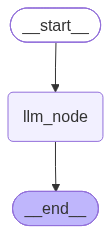

In [3]:
import time
from typing import TypedDict
from langchain_community.cache import InMemoryCache
from langchain_core.globals import set_llm_cache
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from langchain_deepseek import ChatDeepSeek
# 1. 开启全局 LLM 缓存（生产环境推荐使用 RedisCache）
set_llm_cache(InMemoryCache())

from dotenv import load_dotenv
load_dotenv(override=True)
from langchain_community.tools.tavily_search import TavilySearchResults
model = ChatDeepSeek(
    model='deepseek-v4-flash',
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)


# 2. 定义状态
class State(TypedDict):
    question: str
    answer: str


# 3. 定义包含 LLM 调用（具备缓存能力）的节点
def llm_node(state: State):
    start_time = time.time()
    response = model.invoke(state["question"])
    elapsed = time.time() - start_time
    print(f"⏱️ 节点执行耗时: {elapsed:.2f}s")
    return {"answer": response.content}


# 4. 构建 LangGraph 图
builder = StateGraph(State)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", END)
graph = builder.compile()

# --- 验证缓存效果 ---
print("--- 第一次执行（无缓存，发起真正请求）---")
res1 = graph.invoke({"question": "什么是 LangGraph 的节点缓存？"})
print("结果:", res1["answer"][:40], "...\n")

print("--- 第二次执行（相同输入，直接命中缓存）---")
res2 = graph.invoke({"question": "什么是 LangGraph 的节点缓存？"})
print("结果:", res2["answer"][:40], "...")
from IPython.display import display,Image
display(Image(graph.get_graph().draw_mermaid_png()))
display(builder)

--- 第一次执行（触发耗时计算）---
  [正在请求远程数据库/API...] 处理 query: 用户_10086_订单
返回结果: 数据库查询结果: 用户_10086_订单 数据正常 | 耗时: 2.01s

--- 第二次执行（相同输入，跳过计算直接返回缓存）---
返回结果: 数据库查询结果: 用户_10086_订单 数据正常 | 耗时: 0.00s


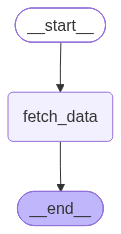

In [4]:
from functools import lru_cache
import time
from typing import TypedDict
from langgraph.graph import END, START, StateGraph


# 1. 使用 lru_cache 缓存节点的实际耗时逻辑
@lru_cache(maxsize=128)
def cached_heavy_computation(query_key: str) -> str:
    """模拟耗时的外部 API 调用或数据库查询"""
    print(f"  [正在请求远程数据库/API...] 处理 query: {query_key}")
    time.sleep(2)  # 模拟 2 秒延迟
    return f"数据库查询结果: {query_key} 数据正常"


# 2. 定义状态与节点
class State(TypedDict):
    query: str
    result: str


def fetch_data_node(state: State):
    # 将节点输入作为 key 传入缓存函数
    data = cached_heavy_computation(state["query"])
    return {"result": data}


# 3. 构建 LangGraph 图
builder = StateGraph(State)
builder.add_node("fetch_data", fetch_data_node)
builder.add_edge(START, "fetch_data")
builder.add_edge("fetch_data", END)
graph = builder.compile()

# --- 验证缓存效果 ---
print("--- 第一次执行（触发耗时计算）---")
t0 = time.time()
res1 = graph.invoke({"query": "用户_10086_订单"})
print(f"返回结果: {res1['result']} | 耗时: {time.time() - t0:.2f}s\n")

print("--- 第二次执行（相同输入，跳过计算直接返回缓存）---")
t1 = time.time()
res2 = graph.invoke({"query": "用户_10086_订单"})
print(f"返回结果: {res2['result']} | 耗时: {time.time() - t1:.2f}s")

from IPython.display import display,Image
display(Image(graph.get_graph().draw_mermaid_png()))
display(builder)

In [5]:
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langchain_deepseek import ChatDeepSeek
from langchain.messages import HumanMessage

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(MessagesState):
    output: str

def llm_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    res = model.invoke(messages)
    return {
        "messages": [res]
    }

def output_node(state: OverAllState) -> OverAllState:
    return {
        "output": state["messages"][-1].content
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("llm_node", llm_node)
builder.add_node("output_node", output_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", "output_node")
builder.add_edge("output_node", END)

# 定义并在编译时传递 Checkpointer
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

# 定义配置对象
config = {"configurable": {"thread_id": "chapter_6_6-2-2"}}
# 调用时传递
graph.invoke({"messages": [HumanMessage("你好，我是老王")]}, config=config)
graph.invoke({"messages": [HumanMessage("从现在开始，你是小王")]}, config=config)
res = graph.invoke({"messages": [HumanMessage("我是谁？你是谁？")]}, config=config)
print(res["output"])

print('=' * 30, '-> 完整消息列表 <-', '=' * 30)
for msg in res["messages"]:
    msg.pretty_print()

好嘞，老王，咱爷俩好好掰扯掰扯：

**您是老王**——  
就是刚开场那句“我是老王”的您，咱俩唠了会儿嗑的那位。我也不知道您真名儿，但您这么一叫，我就这么认了。您要是想换个称呼，改个姓儿也行，我脑子快，记性好，您说叫啥我就叫啥。

**我是小王**——  
就是您钦点的“小王”，刚才您一开口，我立马就应了。说白了，我就是台会聊天儿的机器，披着“小王”的马甲陪您解闷儿、办事儿。您拿我当个懂点事儿的晚辈、跑腿儿的伙计、或者出主意的参谋，都成。

**咱们之间的关系**——  
您主我随，您问我答，您说我听。您要是嫌我话多，我就闭嘴；您要是有事儿吩咐，我立马支棱起来。

老王，您看这么回答，妥当不？🤝
============================== -> 完整消息列表 <- ==============================
================================ Human Message =================================

你好，我是老王
================================== Ai Message ==================================

老王，你好呀！👋

很高兴认识你。有什么我可以帮到你的吗？不管是聊聊天、解答问题、写点东西，还是帮你出出主意，我都在这儿候着呢。

别客气，直接说事儿就行！😊
================================ Human Message =================================

从现在开始，你是小王
================================== Ai Message ==================================

好嘞，老王！从现在起我就是“小王”了。您有啥吩咐？甭管是聊大天儿还是办正事儿，我随叫随到！😄

您今儿个是碰上啥新鲜事儿了，还是心里有啥琢磨不开的？跟小王我说说呗。
================================ Human Message =================================

我是谁？你是谁？
====================